In [1]:
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from scipy.optimize import newton

import posydon.utils.constants as const
from posydon.popsyn.synthetic_population import Population
from posydon.utils.common_functions import roche_lobe_radius

import sys
sys.path.append('/home/users/a/aguetar1/')
from XRB_functions import *

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
pop1_GRMHD = Population('1e+00_Zsun_population.h5')
pop01_GRMHD = Population('1e-02_Zsun_population.h5')
pop0001_GRMHD = Population('1e-04_Zsun_population.h5')

In [3]:
display(pop1_GRMHD.oneline.select(columns=['state_f', 'S1_state_f', 'S2_state_f', 'metallicity']))

,state_f,S1_state_f,S2_state_f,metallicity
binary_index,,,,
0,merged,NS,massless_remnant,1.0
1,detached,H-rich_Core_H_burning,H-rich_Core_H_burning,1.0
2,initially_single_star,NS,massless_remnant,1.0
3,merged,NS,massless_remnant,1.0
4,initially_single_star,NS,massless_remnant,1.0
...,...,...,...,...
999995,initial_RLOF,stripped_He_non_burning,H-rich_Core_H_burning,1.0
999996,disrupted,NS,WD,1.0
999997,detached,BH,BH,1.0


In [4]:
# ONLY DO IT ONCE !!!
pop1_GRMHD.calculate_formation_channels(mt_history=True)
pop01_GRMHD.calculate_formation_channels(mt_history=True)
pop0001_GRMHD.calculate_formation_channels(mt_history=True)

In [4]:
pop1_GRMHD_XRB = pop1_GRMHD.create_transient_population(lambda h, o, f: XRB_selection_function(h, o, f, wind_disk_formation=False, Vwind_scheme='Kudritzki+2000', Wind_fed_scheme = 'HiraiMandel21'), 'GRMHD_Pop1_XRB')
pop01_GRMHD_XRB = pop01_GRMHD.create_transient_population(lambda h, o, f: XRB_selection_function(h, o, f, wind_disk_formation=False, Vwind_scheme='Kudritzki+2000', Wind_fed_scheme = 'HiraiMandel21'), 'GRMHD_Pop01_XRB')
pop0001_GRMHD_XRB = pop0001_GRMHD.create_transient_population(lambda h, o, f: XRB_selection_function(h, o, f, wind_disk_formation=False, Vwind_scheme='Kudritzki+2000', Wind_fed_scheme = 'HiraiMandel21'), 'GRMHD_Pop0001_XRB')

overwriting transient population
overwriting transient population
overwriting transient population


In [8]:
display(pop1_GRMHD_XRB.population)

,time,time_of_birth,metallicity,state_final,Accretor_state,Accretor_mass,Accretor_logR,Accretor_logMdot,Accretor_spin,Donor_state,...,Donor_H1_surface_content,Donor_He_core_mass,Orbital_period,Eccentricity,Log_Mtransfer_rate,Mdot_BHL_gps,Mdot_RLO_gps,Beaming,Edd_State,Lx_Total
49,65.948539,53.046815,1.0,initial_RLOF,NS,1.382283,-4.745687,NaN,0.000000,H-rich_Core_H_burning,...,7.155000e-01,0.000000,99.578010,0.886888,NaN,0.000000e+00,0.000000e+00,1.0,Sub-Eddington,0.000000e+00
90,63.965378,59.017580,1.0,initial_RLOF,BH,10.203363,-4.363382,NaN,0.202109,H-rich_Core_H_burning,...,7.154999e-01,0.000000,4.165820,0.264500,NaN,0.000000e+00,0.000000e+00,1.0,Sub-Eddington,0.000000e+00
323,93.868999,50.517440,1.0,initial_RLOF,NS,1.336778,-4.745687,-7.662044,0.000045,stripped_He_non_burning,...,1.000000e-02,1.820082,0.037684,0.000000,NaN,0.000000e+00,0.000000e+00,1.0,Sub-Eddington,1.948746e+38
344,46.077924,33.605371,1.0,initial_RLOF,NS,1.460235,-4.745687,NaN,0.000000,H-rich_Core_H_burning,...,7.155000e-01,0.000000,3.516759,0.925469,NaN,0.000000e+00,0.000000e+00,1.0,Sub-Eddington,0.000000e+00
431,100.000000,93.838540,1.0,detached,BH,19.118788,-4.090665,-98.698970,0.284339,stripped_He_Core_He_burning,...,3.496181e-45,9.779437,86.043092,0.000000,-99.0,0.000000e+00,6.303285e-74,1.0,Sub-Eddington,7.768208e-54
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
999693,29.097445,9.352653,1.0,initial_RLOF,NS,1.322990,-4.745687,NaN,0.000000,H-rich_Core_H_burning,...,7.155000e-01,0.000000,9.151508,0.994577,NaN,0.000000e+00,0.000000e+00,1.0,Sub-Eddington,0.000000e+00
999713,100.000000,34.009047,1.0,detached,NS,1.398747,-4.745687,-99.000000,0.000000,H-rich_Core_H_burning,...,7.155000e-01,0.000000,132.036052,0.924197,NaN,2.058084e+10,0.000000e+00,1.0,Sub-Eddington,9.364380e-54
999890,100.000000,18.925074,1.0,detached,NS,1.278944,-4.745687,-99.000000,0.000000,H-rich_Core_H_burning,...,7.155000e-01,0.000000,31.848321,0.620565,NaN,5.660859e+09,0.000000e+00,1.0,Sub-Eddington,8.562316e-54
999899,100.000000,44.189882,1.0,detached,NS,1.150693,-4.745687,-99.000000,0.000000,H-rich_Core_H_burning,...,7.155000e-01,0.000000,865.836206,0.959778,NaN,2.792089e+08,0.000000e+00,1.0,Sub-Eddington,7.703697e-54


#### Plots

- 1 Zsun

/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/synthetic_population.py:1965: OverwriteWarning: 'Model weights already exist! Overwriting them!'


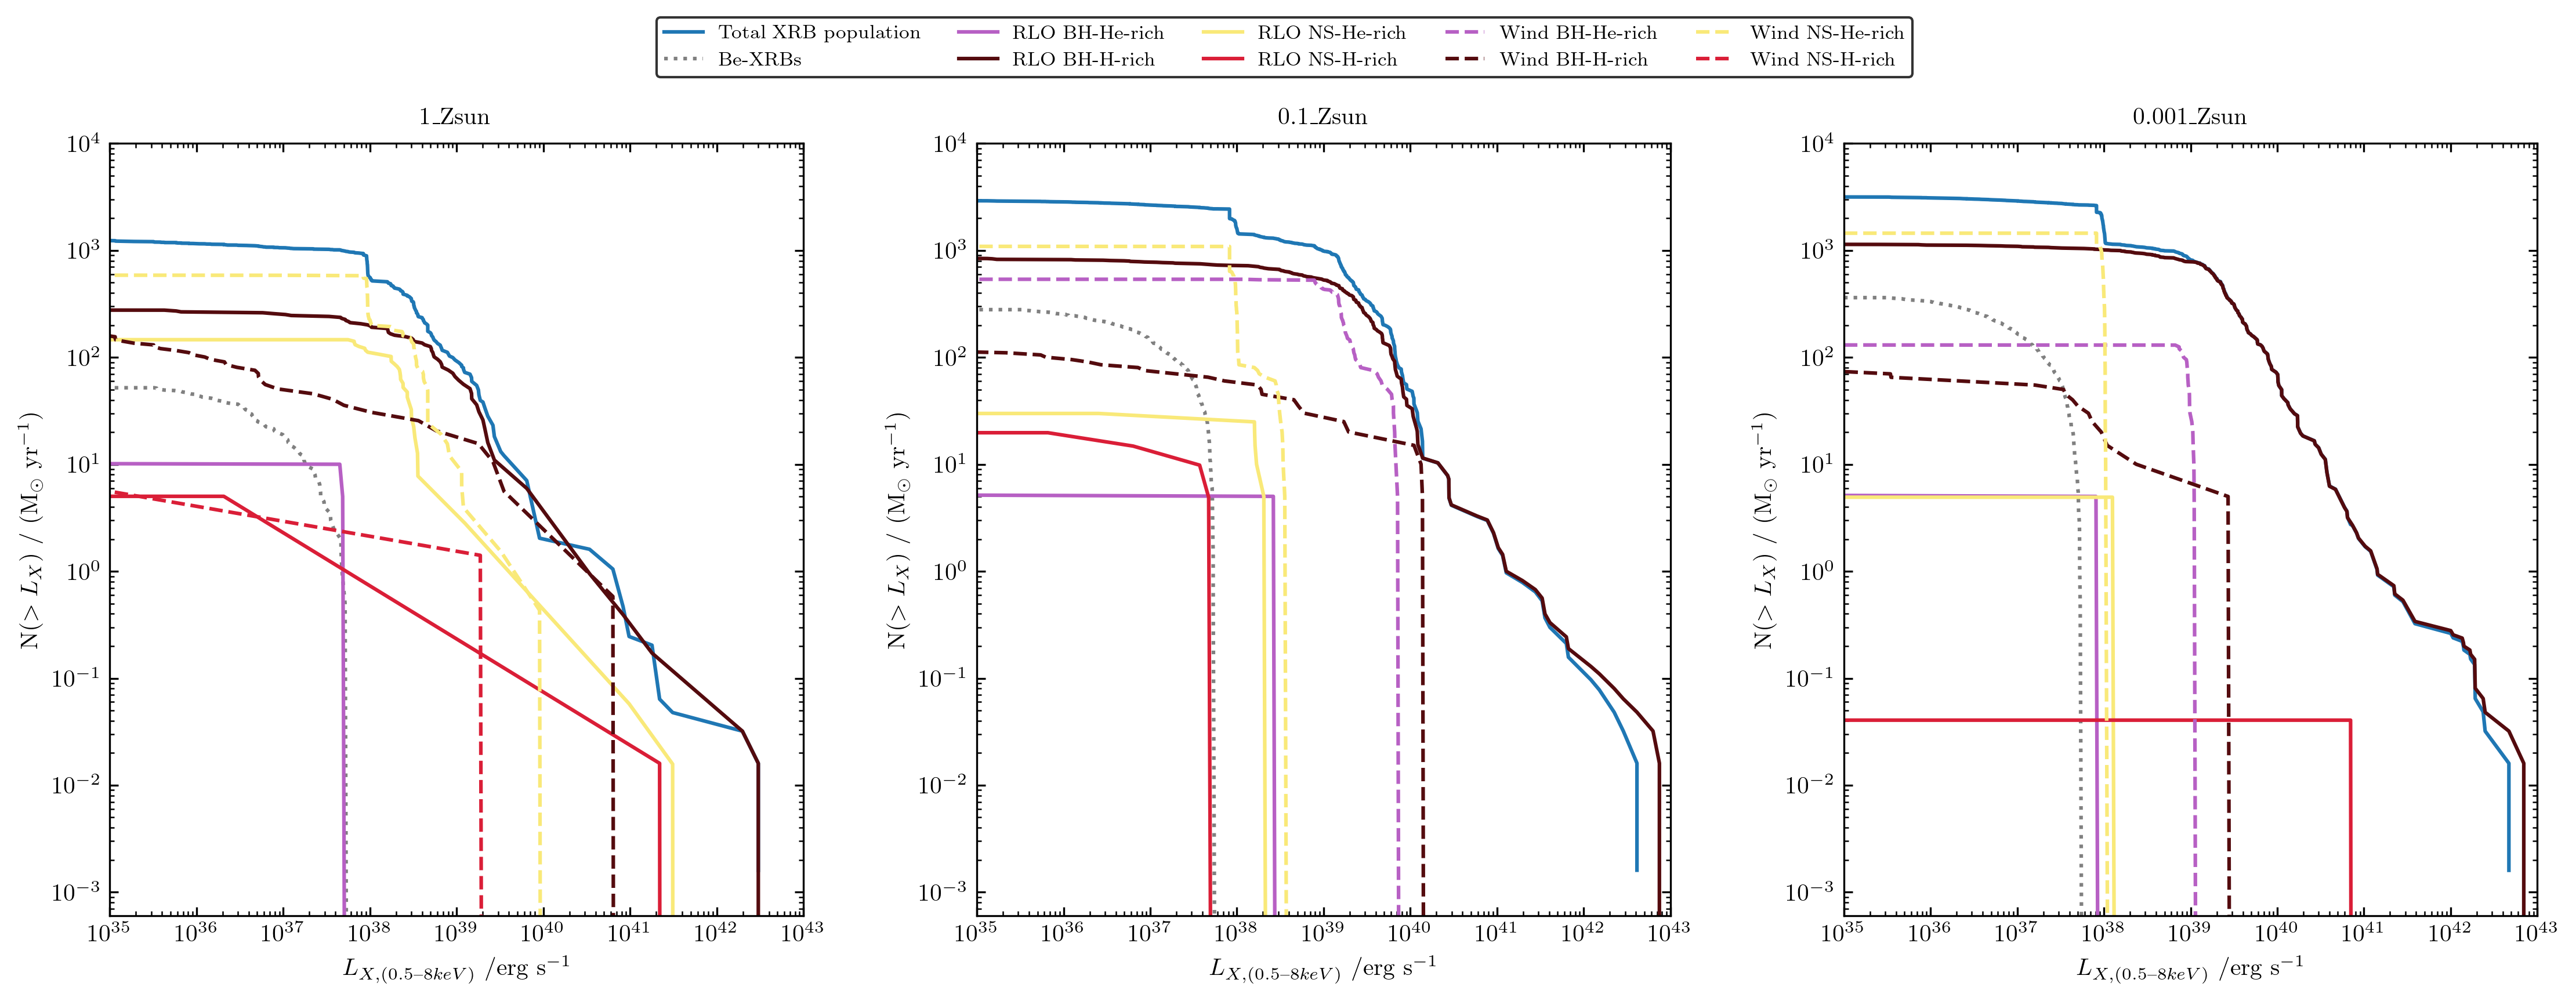

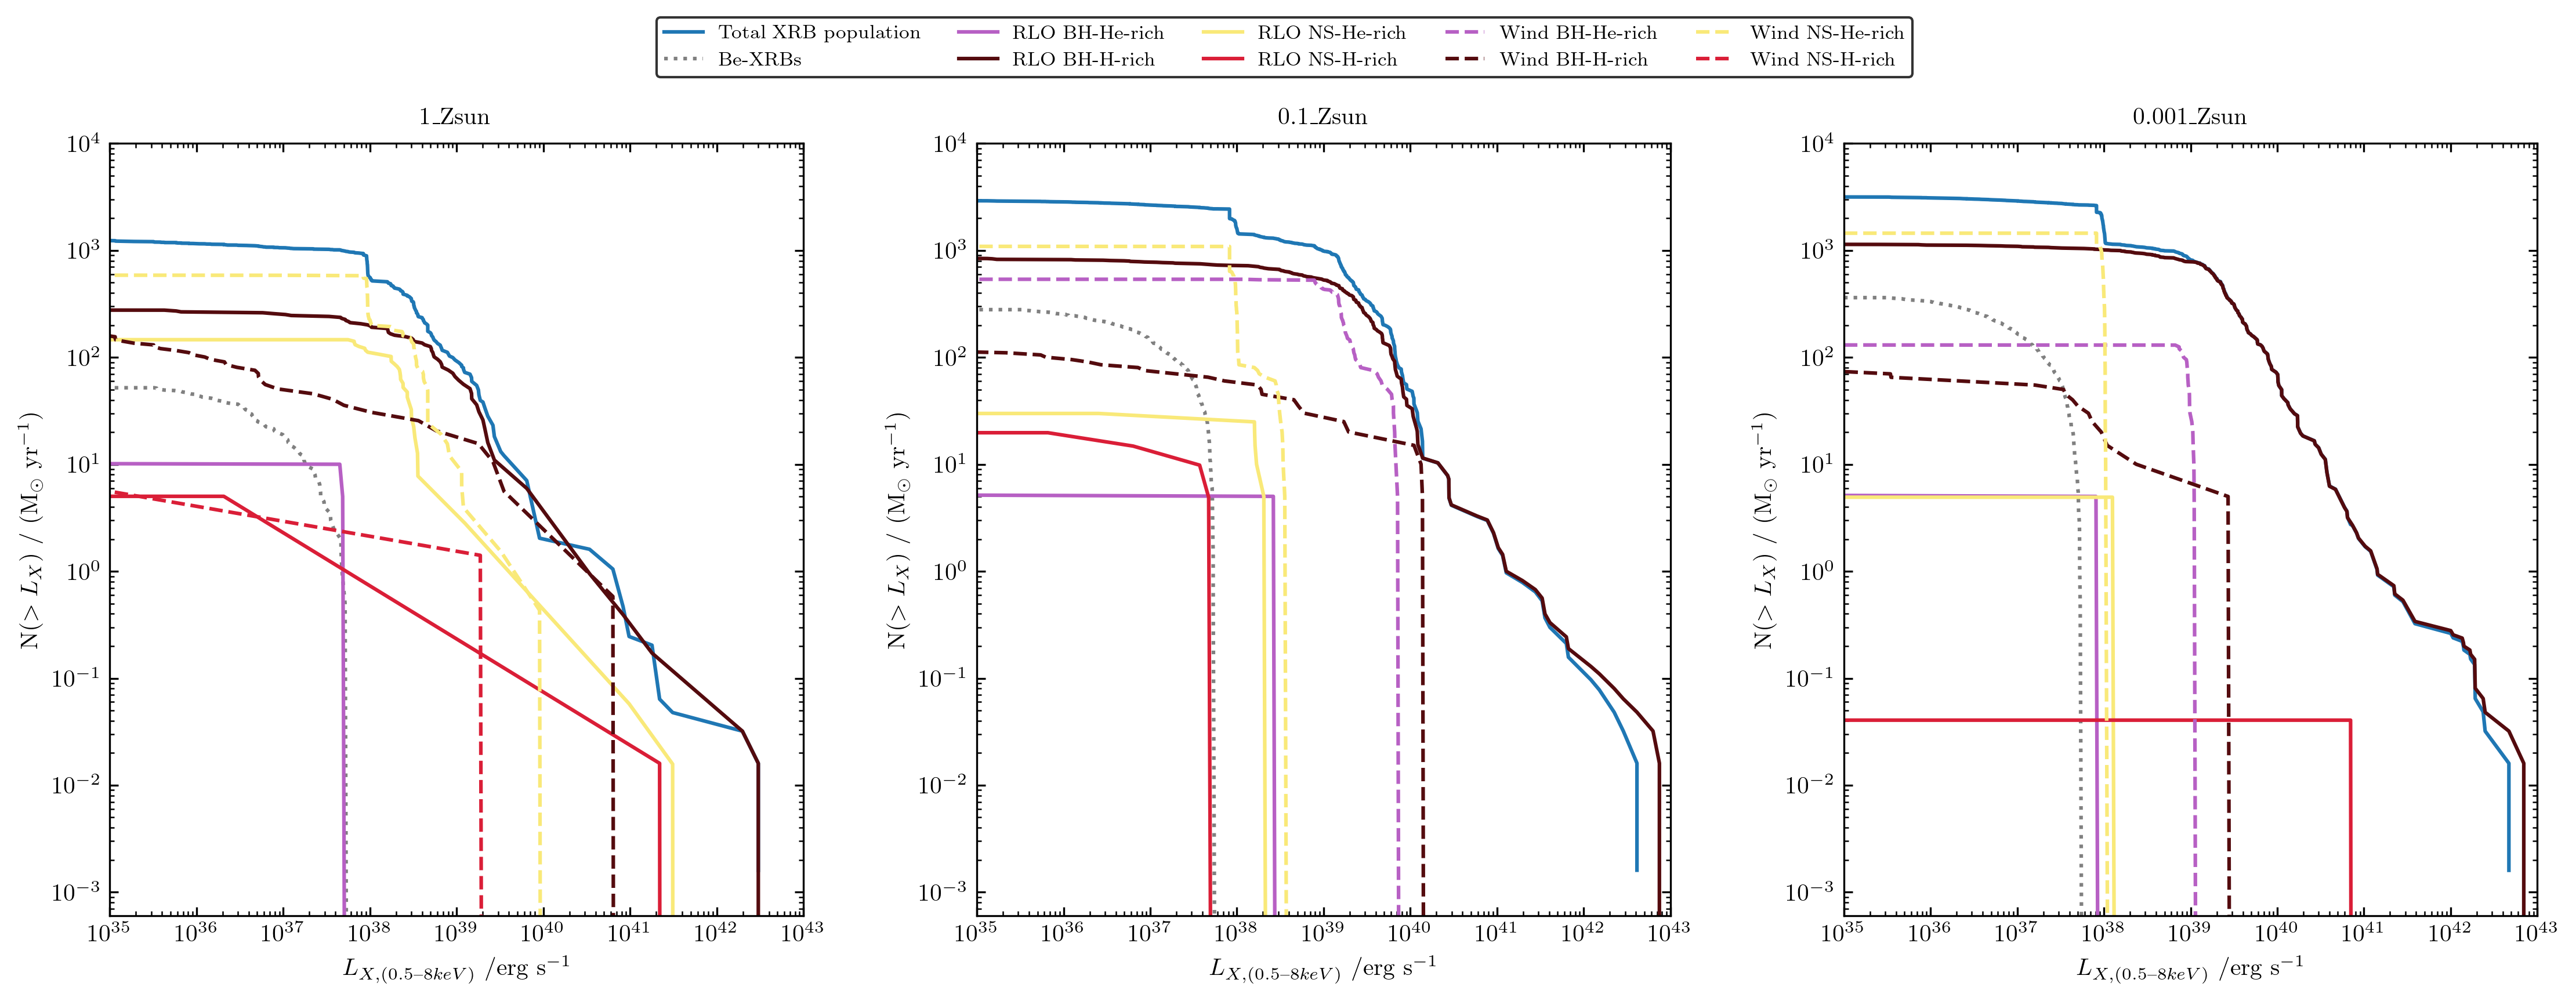

In [ ]:
stat_kwargs = {'primary_mass_min': 0.01,
               'primary_mass_max': 200.0,
               'q_min': 0.0,
               'q_max': 1.0,}

ylims = [(6e-4, 1e4),(6e-4, 1e4),(6e-4, 1e4)]

models = [('1 Zsun', pop1_GRMHD_XRB), ('0.1 Zsun', pop01_GRMHD_XRB), ('0.001 Zsun', pop0001_GRMHD_XRB)]

plot_XLF_models(models, ncols=3, figsize=(18,6),ylims=ylims, stat_kwargs=stat_kwargs)